## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Amelia Chen

**Date:** 10/9/2026

In [1]:
########## ========== Q1.1 ========== ##########
# Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. 
# Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, 
# from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

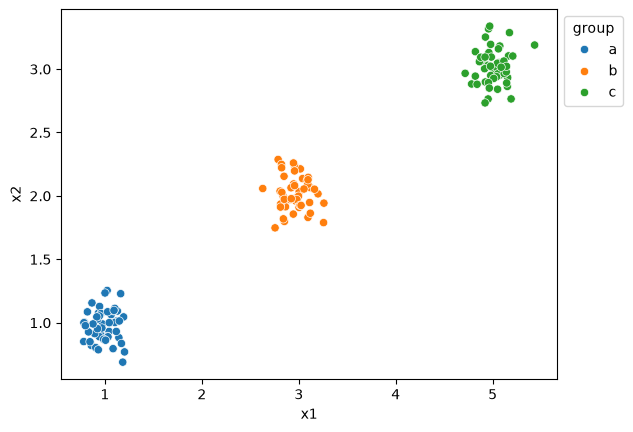

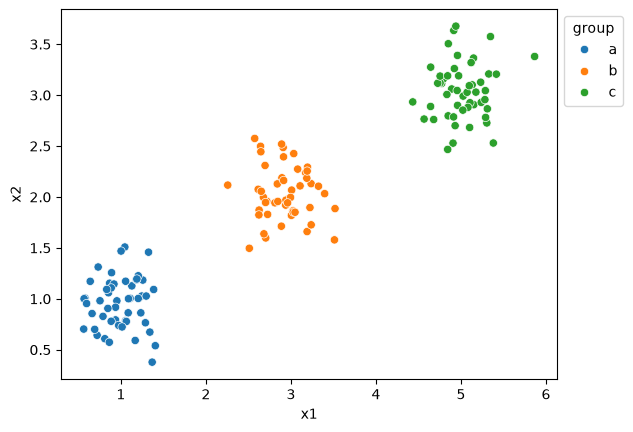

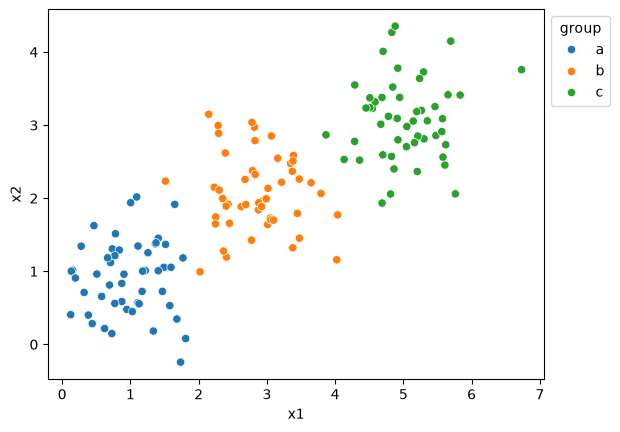

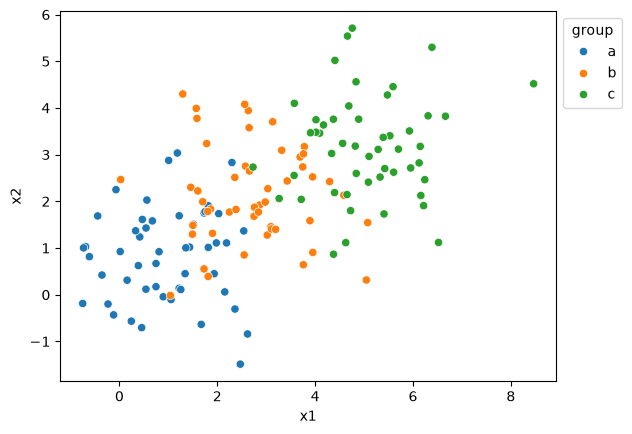

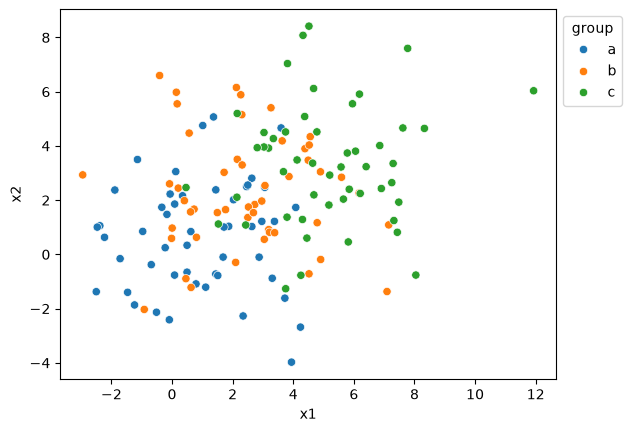

In [ ]:
########## ========== Q1.2 ========== ##########
# Make scatterplots of the (X1,X2) points by group for each of the datasets. 

plt.figure()
ax = sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.savefig("df0_125_scatterplot.png")
plt.show()

plt.figure()
ax = sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.savefig("df0_25_scatterplot.png")
plt.show()

plt.figure()
ax = sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.savefig("df0_5_scatterplot.png")
plt.show()

plt.figure()
ax = sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.savefig("df1_0_scatterplot.png")
plt.show()

plt.figure()
ax = sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.savefig("df2_0_scatterplot.png")
plt.show()

##### **As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?**

As the noise increases from 0.125 to 2.0, the visual distinctness of the clusters decreases.
When the noise is 0.125, the clusters are tight and distinct.
When the noise is 0.25, the clusters have started to spread out to about twice the area, but there is still space between the clusters to distinguish them. When the noise is 0.5, the points on the outer edges of each group have started to mesh with each other. The boundary between the clusters for group a and group b are less distinguishable than the boundary between group b and group c. At this point, if we were to remove the hue and try to split each of the clusters up, we would likely make some mistakes, especially between group a and b. When the noise is 1.0, each clusters has spread out to have roughly half of their points overlap with the adjacent group. If we were to remove the hue now, the clusters would be completely indistinguishable. Finally, when the time the noise level has reached 2.0, the plot looks similar to the 1.0 noise scatterplot, just further exaggerated. The groups have spread out to the point that points in group a have started to overlap with points in group c. Again, if we were to remove the hue, the clusters would be even further indisinguishable.

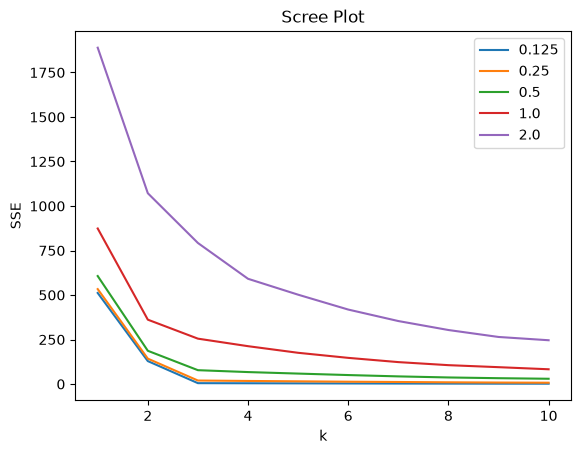

In [122]:
########## ========== Q1.3 ========== ##########
# Create a scree plot for each of the datasets. 
# (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

# Source: https://stackoverflow.com/questions/55981638/how-to-create-a-legend-for-a-seaborn-lineplot-with-two-separately-calculated-lin
from sklearn.cluster import KMeans

# drop the group column from each of the dataframes so we are left with the numerical x1 x2 data of the points
scree0_125 = df0_125.drop("group", axis=1)
scree0_25 = df0_25.drop("group", axis=1)
scree0_5 = df0_5.drop("group", axis=1)
scree1_0 = df1_0.drop("group", axis=1)
scree2_0 = df2_0.drop("group", axis=1)

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree0_125).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '0.125').set(title="Scree Plot", xlabel="k", ylabel="SSE")

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree0_25).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '0.25')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree0_5).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '0.5')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree1_0).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '1.0')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree2_0).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '2.0')

plt.legend()


##### Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$.

Note: by commenting out the curve for scree2_0 we are able to observe that the curve for scree1_0 is the same and hidden underneath it.

The curve for noise level 0.125 shows SSE starting around 500 at k=1, dropping to ~125 at k=2, dropping again to near 0 at k=3, and remaining constant for the remaining k values. The curve for noise level 0.25 sits slightly above the former curve: the SSE at points k=1, k=2, and k=3 are marginally higher, then between k=3 to k=10 the SSE very gradually decreases from above 0 to near 0. At noise level 0.5, we see a large jump between the curves. At k=1, SSE is now around 600. At k=2, SSE is closer to ~200. At k=3, SSE is closer to ~75. Similarly to noise=0.25, the curve from k=3 to k=10 steadily and gradually decreases, however it does not reach near 0 and is closer to SSE=~50. At noise level 1.0 and 2.0, there is an even greater jump between the curves. SSE starts at above 800 at k=1, drops to ~350 at k=2, then drops to ~250 at k=3. The slope of the curve between k=3 to k=10 is notably steeper than the other curves, falling from ~250 to ~100.

In general, across all the curves, we see 2 elbows, one at k=2 and another at k=3. The drop between SSE at k=1 and k=2 is very steep, and compartively the drop between k=2 and k=3 is much more shallow. Across all curves, at k=2, the elbow is quite clear, however at k=3, the angle of the elbow gradually becomes more obtuse as the noise increases. This is particularly evident when we compare the curves for noise level 0.5 and 1.0/2.0: the elbow at k=3 in the 0.5 curve is sharp because the drop between k=3 to k=10 is quite shallow, however in the 1.0/2.0 curve the elbow at k=3 is close to being indistinguishable from the rest of curve from k=3 to k=10.

When trying to choose a k, it is very clear in the scree plots of noise levels 0.125, 0.25, and 0.5 that k=2 or k=3 would be ideal. The initial curve from k=1 to k=2 significantly reduces the SSE, and from k=2 to k=3 there is another distinct drop. The curves after k=3, especially in the 0.125 and 0.25 plots, show very slight improvements in reducing the SSE. This demostrates that 2 clusters may begin to show the distinctions in the data, and 3 clusters is sufficient to separate most of the observations, and anything more than 3 is unnecessary as it introduces more clusters with minimal improvement. This becomes less clear in the curve for noise levels 1.0 and 2.0: while there is still a steep drop between k=1 and k=2, the drop between k=2 and k=3 and much less distinct, and the improvements in reducing the SSE following k=3 are steeper. Additionally, the SSE in these curves is overall significantly greater. From k=2 to k=3, the SSE drops from ~350 to ~250: both of these SSE's are quite large. From k=3 to k=10, the SSE drops from ~250 to ~100. This makes the case for k=2 stronger, as it brings the most significant decrease to the SSE, but it also makes the case for k=4 to k=10 stronger, as these k values continue to decrease the SSE in a way that may be considered significant/meaningful. In general, with a higher noise level, there is a reduced ability to definitely select a k.



##### Q1.4: Explain the intuition of the elbow, using this numerical simulation as an example.

The elbow shows a tradeoff between number of clusters and error. We want to figure out how many clusters we need to accurately classify the observations. In general, for clustering, increasing the number of clusters decreases the error: we observe this phenomenon well in the curve for noise levels 1.0 and 2.0. However, the elbow can show where increasing k no longer **significantly** improves the error. When increasing k no longer significantly decreases the error, it indicates that we have captured the underlying patterns in the data to a sufficient enough point that if we were to continue to increase k, it would bring little benefit. There may be multiple elbows in the curve, and the elbow we choose is dependent on the type of analyses we intend to do.

In this example, we know that we have 3 groups (a, b, and c), so let's say that our objective is not to assess the relationship between x1 and x2 but to separate and compare the observations. We need to determine how many clusters is "sufficient" in capturing the underlying patterns. In the simulation, we observed elbows at k=2 and k=3. In the curves for noise level 0.125 and 0.25, the choice of k=3 is obvious as the SSE at these points is close to 0. Since we want to separate the observations, k=3 gives us the cleanest separation with the fewest clusters. In the curve for noise levels 0.5/1.0/2.0, although we already talked about the fact that increased noise makes it more difficult to select a distinct k, we are still likely to choose k=3. The presence of an elbow at k=3 indicates that the improvement following it is minimal- even though the elbow is much harder to see in the curves for 1.0/2.0, it is still there, and we should choose the greatest k value that is also an elbow to ensure we are maximizing the separation between observations. The elbow at k=2 is stronger, but in this context we can conclude that the drop between k=2 and the elbow at k=3 is still mearningful for separating the observations. Using the elbow intuition to choose k, we end up with k=3 which is the same as the known number of groups we started with.

In [ ]:
########## ========== Q2.1 ========== ##########
# Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. 
# Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. 
# Is any further cleaning of the variables required?

# Sources:
# https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html
# https://numpy.org/devdocs/reference/generated/numpy.round.html

filepath = 'data/SIPRI Military Expenditure Database.csv'
df = pd.read_csv(filepath, low_memory=False)

# print(df.shape, '\n')   # output: (5882, 7)
# print(df.info())

'''
Output:

<class 'pandas.DataFrame'>
RangeIndex: 5882 entries, 0 to 5881
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           5882 non-null   int64  
 1   Year                            5882 non-null   int64  
 2   Country                         5882 non-null   str    
 3   Spending (2020 USD)             4863 non-null   float64
 4   Percent of GDP                  4881 non-null   float64
 5   Percent of Government Spending  4210 non-null   float64
 6   Spending per Capita             4835 non-null   float64
dtypes: float64(4), int64(2), str(1)
memory usage: 321.8 KB
None
'''

working_df = df.copy()      # make a copy of the original dataframe

working_df = working_df[working_df['Year'] == 2020]     # select only the rows where the Year columns is 2020
working_df.dropna(inplace=True)     # drop the rows with missing values

# print(working_df.shape, '\n')   # output: (148, 7). confirmed that we ended up with 148 entries
# print(working_df.info())    # confirmed that in all columns, all entries are non-null

'''
Output:
<class 'pandas.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    str    
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), str(1)
memory usage: 9.2 KB
None
'''

# look at the value counts of each columns besides Year to see if any additional cleaning show be done
with pd.option_context('display.max_rows', None):

    #print(working_df["Country"].value_counts())    

    '''
    There are some inconsistencies in country names that are more than one word.
    I decide to clean the Country Names based on Wikipedia's list of countries: https://simple.wikipedia.org/wiki/List_of_countries

    Changes:
    1. Congo, DR -> Democratic Republic of the Congo
    2. Congo, Republic -> Republic of the Congo
    3. Korea, South -> South Korea
    '''

    #print(working_df["Spending (2020 USD)"].value_counts())
    #print(working_df["Percent of GDP"].value_counts())
    #print(working_df["Percent of Government Spending"].value_counts())
    #print(working_df["Spending per Capita"].value_counts())

    # nothing too unusual based on the value counts. all decimal values, no negatives

# cleaning the Country column
working_df = working_df.replace("Congo, DR", "Democratic Republic of the Congo")
working_df = working_df.replace("Congo, Republic", "Republic of the Congo")
working_df = working_df.replace("Korea, South", "South Korea")

# checking after cleaning
#with pd.option_context('display.max_rows', None):
#    print(working_df["Country"].value_counts())

# use describe to check for outliers or unusual values
working_df.describe()

# decided to remake the index column since it has values leftover from before initial cleaning
working_df["index"] = range(len(working_df))

'''
As it makes sense that spending would range a lot between country to country, it is difficult to identify specific 
"unusual" data points from just the describe function alone. We are able to observe a few general patterns though:
the mean is consistently higher than the 50% quartile across all columns, this indicates that there are some large
values that are skewing the data to the right. Notably, the largest differences in the mean and 50% quartile are in
the Spending (2020 USD) and Spending per Capita columns. In these columns in particular, the lack of consistent 
distribution is further corroborated by the standard deviation, which are significantly larger than the mean. We also 
see some big jumps between quartiles across all columns, usually between the min -> 25% and 75% to max, indicating 
that there are both small and large extremes which create a wide range in the data scales.
'''


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,73.500000,2020.0,13153.747670,0.019619,0.061510,268.264494
std,42.868014,0.0,68005.236120,0.015033,0.046207,430.434878
min,0.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,36.750000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,73.500000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,110.250000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,147.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


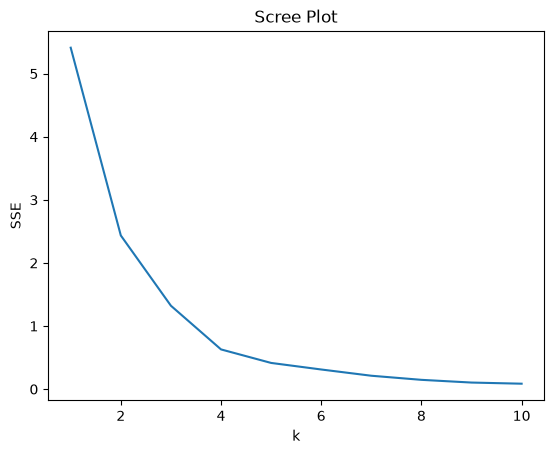

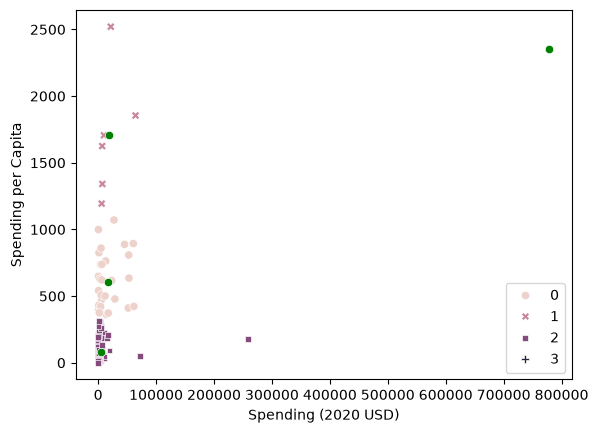

cluster                               0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.880549   
                    50%      579.004604   1665.447478      47.056944   
                    75%      757.328513   1817.219993     125.387558   
                    max     1070.623322   2520.398541     314.201312   

cluster                                3  
Spending (2020 USD) count       1.000000  
                    mean   778397.200000  
                    std              NaN  
                    min    778397.200000  
                    25%    778397.200000  
                    50%    778397.200000  
                    75%    778397.200000  
                    max    778397.200000  
Spending per Capita count       1.000000  
                    mean     2351.631858  
                    std              NaN  
                    min      2351.631858  
                    25%      2351.631858  
                    50%      2351.631858  
                    75%      2351.631858  
                    max      2351.631858

In [118]:
########## ========== Q2.2 ========== ##########
# Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. 
# Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. 
# Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. 
# Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). 

from sklearn.cluster import KMeans

# normalization
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = working_df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])


# create the scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
plt.figure()
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.savefig("Spendings_ScreePlot.png")
plt.show()
optimal_k = 4  
# chose optimal k to be 4. 
# decided that elbow at k=5 is not distinct enough,
# and not significant enough of a drop in SSE from k=4


# create the scatterplot with the number of clusters equal to the optimal k
model = KMeans(
    n_clusters=optimal_k,
    max_iter=300,
    n_init=10,
    random_state=0
).fit(X)
working_df["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
plt.figure()
ax = sns.scatterplot(
    data=working_df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)
plt.savefig("Spendings_ScatterPlot.png")
plt.show()

# describe based on cluster membership
describe_features = ["Spending (2020 USD)", "Spending per Capita", "cluster"]
working_df.loc[:, describe_features].groupby("cluster").describe().T

# printing the data for the United States
# print(working_df.loc[working_df["Country"] == "United States of America"])
# Output: Spending (2020 USD)-778397.2, Spending per Capita-2351.631858, cluster-3


##### What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

We see that most of the points are on the left side of the graph, with a Spending (2020 USD) between 0 and 100,000. The points are densest in the bottom left, and gradually become more sparse as you move up to the top left.

Cluster 2 has its centroid in the bottom left corner, with most points closer to 0 on the Spending (2020 USD) axis and falling between 0-400 on the Spending per Capita axis. Specifically, the range of Spending per Capita is 0.580129-314.201312. There are a few outliers with respect to Spending (2020 USD) in this cluster: one has a Spending (2020 USD) of ~75,000, and the other sits at 257973.429834. The average Spending (2020 USD) is 4859.185065, and the median is 382.464677. The standard deviation is 22861.507114. The average Spending per Capita is 80.061470, and the median is 47.056944. The standard deviation is 466.375705. Mean for both are high; standard deviation for Spending (2020 USD) is much higher than the mean but relatively close for Spending per Capita. Additionally, the range for Spending (2020 USD) is wide. For both, the jumps between min -> 25% -> 50% are smaller, then between 50% -> 75% -> max the size of the differences gradually increases, especially in Spending (2020 USD). Overall, the countries in this cluster have both low Spending (2020 USD) and low Spending per Capita, however they have large values along both axes that skew the distribution. There are two outliers with high Spending (2020 USD) but low Spending per Capita. This cluster has 111/148 points, which is 75% of the total data, so a large majority of the data falls into this cluster.

Cluster 0 has its centroid still in the lower left, but above Cluster 2 at around Spending per Capital = 600. The data points range from around 362.467076-1070.623322 on the Spending per Capita axis. At a glance, the points are more spread out compared to the Cluster 2, but there are no stark outliers on the Spending (2020 USD) axis; all points are within 405.790494 to 61712.537169. The average Spending (2020 USD) is 17077.591354, and the median is 5857.060906. The standard deviation is 20583.053357. The average Spending per Capita is 607.478618, and the median is 579.004604. The standard deviation is 206.928757. In both cases the mean is greater than the median, but significantly more so for Spending (2020 USD). The mean/median for Spending per Capita are actually relatively quite close. We also observe that the standard deviation is greater than the mean for Spending (2020 USD). This means that the Spending per Capita is more evenly distributed, while the Spending (2020) is skewed right. Again, we see the same patterns in differences between quartiles, but it is particularly evident for Spending (2020 USD). Overall, the countries in this cluster have slightly higher but still low Spending (2020 USD), and mid-range Spending per Capital. There are 30/148 points in this cluster, which is ~20.27%. This cluster contains roughly 1/5 of the total data points, but makes up the majority of the remaining points aside from Cluster 2.

Cluster 1 is the last cluster on the left side, encapsulating all remaining points on the left side of the plot. There are significantly less data points in this cluster, and they are much more sparse. Although the centroid sits at around 1,700 on the Spending per Capita axis, the data points range from around 1193.598730-2520.398541. This cluster contains the point with the greatest Spending per Capita, which stands out as an outlier. Similarly to the Cluster 0, all points are within 0 to roughly 65,000 on the Spending (2020 USD) axis. The average Spending (2020 USD) is 19443.362047, and the median is 8624.225729. The standard deviation is 22861.507114. The average Spending per Capita is 1706.721916, and the median is 1665.447478. The standard deviation is 466.375705. Similarly to Cluster 0 the means are both greater than the medians, but much more so for Spending (2020 USD). Notably, the standard deviation for Spending per Capita compared to the other clusters is much greater, although it is not that different relative to mean compared to Cluster 0. The increased standard deviation in Spending per Capita reflects the wide range of values. The differences between 25%-50%-75% quartiles for Spending (2020 USD) is similar to the other clusters, but the differences between 25%-50%-75% quartiles for Spending per Capita is more consistent. There is, however, a big jump between 75% of quartile Spending per Capita and max, which aligns with the observation of an outlier. Overall, this cluster represents the group of countries with high Spending per Capita and low Spending (2020 USD). There are only 6/148 points in this cluster, or ~4.05%.

The final cluster, Cluster 3, has its centroid all the way in the top right corner, at around Spending (2020 USD)=775,000 and Spending per Capita=2,300. When we comment out the code to plot the centroid, we see that there appears to be a singular point at the same position as the centroid. Printing out the information for the United States, we see that it belongs to Cluster 3 and its numbers match the position of this single point. Since there is only one point in this cluster, we cannot analyze the metrics we get from calling the describe function. However, we see that this point has a Spending (2020 USD) of 778397.2 and Spending per Capita of 2351.631858. It has the highest Spending (2020 USD) by far, compared to all other points. Even with the closest point on the Spending (2020 USD) axis there is a difference of 520423.7702. In terms of Spending per Capita, it falls slightly below the outlier in Cluster 1, with a small difference of 168.766683. This cluster represents the countries that have both a high Spending (2020 USD) and a high Spending per Capita.

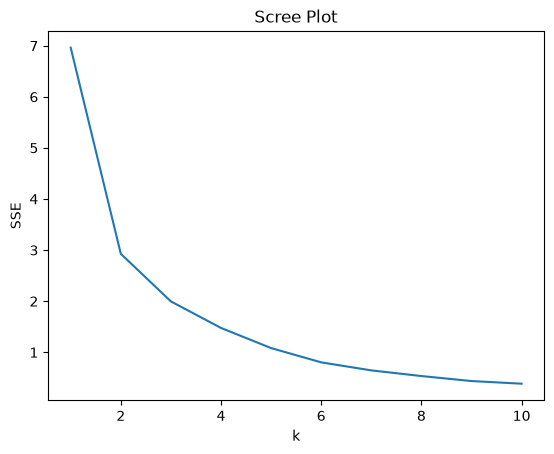

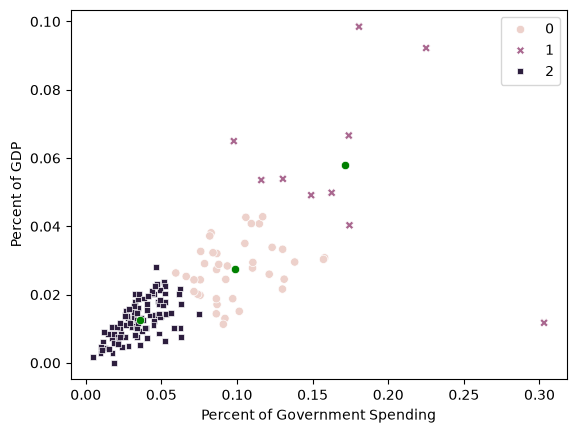

cluster                                       0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                               50%     0.027781   0.053729   0.013191
                               75%     0.032461   0.066190   0.016752
                               max     0.042810   0.098470   0.028132

In [119]:
########## ========== Q2.3 ========== ##########
# Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`.

# normalization
features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = working_df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

# scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
plt.figure()
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.savefig("Percentages_ScreePlot.png")
plt.show()
optimal_k = 3
# chose optimal k to be 3
# elbow is not too distinct, but decided that the drop in SSE from k=2 is significant

# create the scatterplot with the number of clusters equal to the optimal k
model = KMeans(
    n_clusters=optimal_k, 
    max_iter=300,
    n_init=10, 
    random_state=0
).fit(X)
working_df["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
plt.figure()
ax = sns.scatterplot(
    data=working_df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)
plt.savefig("Percentages_ScatterPlot.png")
plt.show()

# describe based on cluster membership
describe_features = ["Percent of Government Spending", "Percent of GDP", "cluster"]
working_df.loc[:, describe_features].groupby("cluster").describe().T

##### How do your results compare to part 2?

While the shape of the scatterplot is completely different, we see a similar overall pattern: points are most dense in the lower left corner, and gradually become more sparse. The difference is that the points in this scatterplot follow a general positive trend along both axes, which tells us that as Percent of Government Spending increases, Percent of GDP also generally increases. In contrast, the scatterplot in part 2 had most of the points only increasing along the y-axis. This general positive trend makes the sparseness of points more evident, as points are spread out along 2 dimensions, vs in part 2 when most of the points were in a similar area of the x-axis.

Cluster 2 is the cluster is the bottom left corner. The centroid is around 0.04 Percent of Government Spending and 0.01 Percent of GDP. For Percent of Government Spending, the data ranges from 0.004896 to 0.074624, and for Percent of GDP the data ranges from 0.000054	to 0.028132. Relative to the rest of the plot, these ranges are pretty small, reflecting the density of the points in this cluster. The average Percent of Government Spending is 0.035777, and the median is 0.034261. The standard deviation is 0.014549. The average Percent of GDP is 0.012664, and the median is 0.013191. The standard deviation is 0.005681. For both, the means are quite close to the medians, and the stardard deviations are less than the mean indicating greater tightness. The differs against Cluster 2 of the previous scatterplot, which despite having most of its points densely clustered as well, had the distribution of both axes skewed, particularly the Spending (2020 USD) on the x-axis which had some outliers. In part 2, the standard deviation was also greater than the mean. For both Percent of Government Spending and Percent of GDP, the jumps between the 25%-50%-75% quartiles are quite stable, and there are some bigger jumps between min-25% and 75%-max. This is pretty similar to what we observed in part 2, as the values at either ends of the extremes create larger distances between the quartiles. There are 99/148 points in this cluster, which is ~66.89% of the total points. Similarly to part 2, the densest cluster holds a large majority of all the points. Overall, the points in this cluster represent the countries with both low Percent of Government Spending and low Percent of GDP.

Cluster 0 is the next cluster when we move in the positive direction. Similarly to the relationship between Cluster 2 and Cluster 0 from part 2, Cluster 0 in this part is less dense and represents a sort of mid-range of the data. The centroid is around 0.10 Percent of Government Spending and 0.03 Percent of GDP. For Percent of Government Spending, the data ranges from 0.059520 to 0.157918, and for Percent of GDP the data ranges from 0.011317 to 0.042810. The ranges of Cluster 0/2 are much closer in this part compared to part 2: In part 2, between Cluster 0/2, along both axes the difference in the range of values expands quite a bit. The average Percent of Government Spending is 0.098683, and the median is 0.092044. The standard deviation is 0.024125. The average Percent of GDP is 0.027412, and the median is 0.027781. The standard deviation is 0.008191. Again, the means are close to the medians and the standard deviations are less than the mean. Just like comparing Cluster 2 across part 2/3, Cluster 0 in this part differs from Cluster 0 from part 2 as the latter was skewed to the right along both axes and had a high standard deviation. Cluster 0 from past 2 also had pretty inconsistent quartiles, with differences that would increase as the quartile increased. Cluster 0 in this part has a similar pattern to Cluster 2 in this part: 25%-50%-75% has relatively stable differences while the differences between the quartiles at either end are more significant. There are 39/148 points in this cluster, or ~26.35%. This is pretty similar to Cluster 0 of part 2, which contained roughly 1/5 of points while this one contains roughly 1/4.

The last cluster is Cluster 1, which only has 10 points, or ~6.76% of total points. This is similar to Cluster 1 of part 2, which had ~4.05% of points. Also similarly, this cluster is visibly much more spread out, and there is one notable outlier. The outlier has a Percent of Government Spending of 0.303027 and a Percent of GDP of 0.011742. The Percent of GDP is barely higher than the Percent of GDP of Cluster 0, which was 0.011317. The outlier also doesn't follow the general positive trend of the overall scatterplot- it stands out a lot because it has both a high Percent of Government Spending and low Percent of GDP. The centroid is around 0.17 Percent of Government Spending and 0.055 Percent of GDP, but the ranges are 0.097882-0.303027 and 0.011742-0.098470 respectively. This is a very large spread compared to Cluster 2. The average Percent of Government Spending is 0.171289, and the median is 0.168248. The standard deviation is 0.058725. The average Percent of GDP is 0.058071, and the median is 0.053729. The standard deviation is 0.024867. Despite the sparseness, the means/medias are still similar and the standard deviations are are both still less than the mean. We do observe larger jumps between the min-25% and 75%-max quartiles, which reflects the greater spread of the data across both axes. These big jumps were something we saw in Cluster 1 of part 2 as well, especially in the jumps between 75% and max. Overall, this cluster represents countries with high Percent of Government Spending and high Percent of GDP.

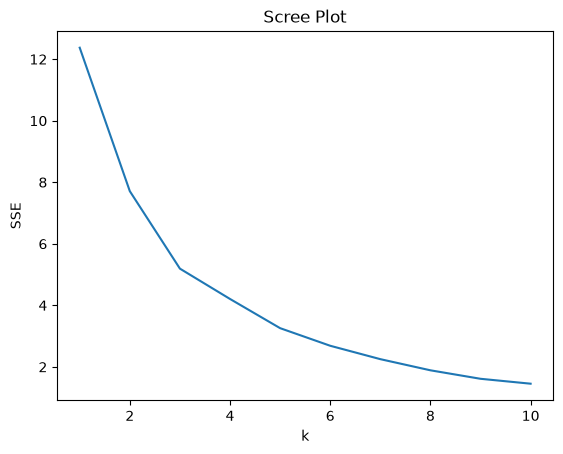

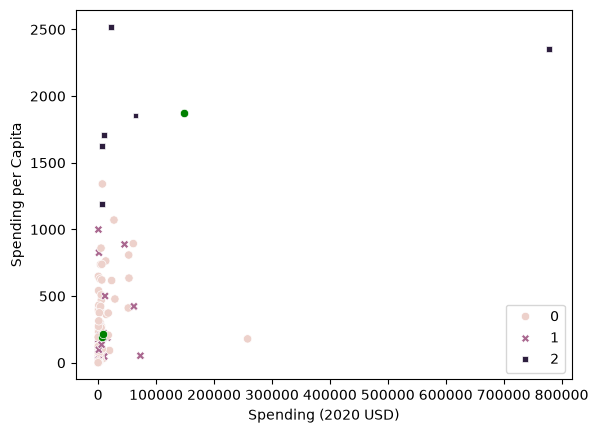

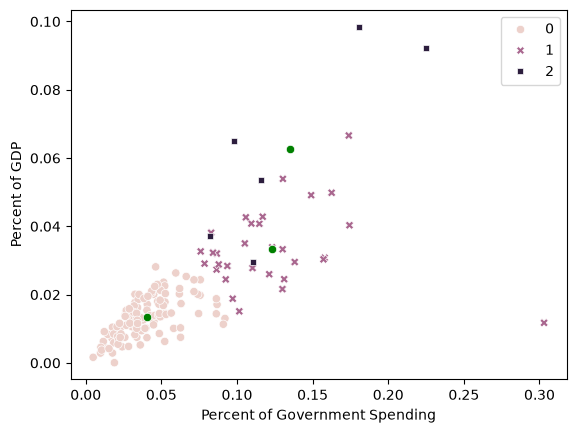

cluster                                           0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%        67.083417    135.459845   
                               75%       295.296094    217.333791   
                               max      1341.058851    998.966186   
Percent of Government Spending count     111.000000     31.000000   
                               mean        0.040350      0.122985   
                               std         0.019320      0.043927   
                               min         0.004896      0.076005   
                               25%         0.026712      0.093093   
                               50%         0.037952      0.114776   
                               75%         0.050505      0.134663   
                               max         0.092044      0.303027   
Percent of GDP                 count     111.000000     31.000000   
                               mean        0.013419      0.033492   
                               std         0.005996      0.011449   
                               min         0.000054      0.011742   
                               25%         0.008873      0.027560   
                               50%         0.013589      0.032024   
                               75%         0.017769      0.040531   
                               max         0.028132      0.066600   

cluster                                           2  
Spending (2020 USD)            count       6.000000  
                               mean   147964.582042  
                               std    309635.189564  
                               min      6095.708713  
                               25%      7700.424616  
                               50%     15897.570598  
                               75%     53872.942442  
                               max    778397.200000  
Spending per Capita            count       6.000000  
                               mean     1875.150751  
                               std       489.800206  
                               min      1193.598730  
                               25%      1645.301864  
                               50%      1780.059564  
                               75%      2227.318999  
                               max      2520.398541  
Percent of Government Spending count       6.000000  
                               mean        0.135351  
                               std         0.055392  
                               min         0.081976  
                               25%         0.101034  
                               50%         0.113271  
                               75%         0.164503  
                               max         0.225050  
Percent of GDP                 count       6.000000  
                               mean        0.062634  
                               std         0.028275  
                               min         0.029429  
                               25%         0.041272  
                               50%         0.059257  
                               75%         0.085

In [120]:
########## ========== Q2.4 ========== ##########
# Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, 
# `Percent of Government Spending`, and `Percent of GDP`. 

features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = working_df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
plt.figure()
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.savefig("All_ScreePlot.png")
plt.show()
optimal_k = 3 
# chose optimal k to be 3
# most pronounced elbow, elbow at k=4/5 not distinct enough


# create scatterplots with the number of clusters equal to the optimal k
model = KMeans(
    n_clusters=optimal_k, 
    max_iter=300, 
    n_init=10, 
    random_state=0
).fit(X)
working_df["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()


plt.figure()
ax1 = sns.scatterplot(
    data=working_df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax1)
plt.savefig("All_ScatterPlot_Spending.png")
plt.show()


plt.figure()
ax2 = sns.scatterplot(
    data=working_df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 2], y=centers[:, 3], color="green", ax=ax2)
plt.savefig("All_ScatterPlot_Percentages.png")
plt.show()

# describe based on cluster membership
describe_features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP", "cluster"]
working_df.loc[:, describe_features].groupby("cluster").describe().T


##### How do your results compare to the previous two parts?

For the Spending (2020 USD) vs Spending per Capita plot, Cluster 0 has a count of 110, similar to Cluster 2 in part 2 which had a count of 111. We observe that two of the centroids are very close together in the bottom left corner, and the last centroid is about 3/4 of the way up along the y-axis and slightly to the right. Cluster 0 contains most of the densely populated points in the bottom left corner. It extends up to 1341.058851 for Spending per Capita, and also contains an outlier at Spending (2020 USD) =  257973.429834. The points in Cluster 0 become less dense as the Spending per Capita increases, they also become less tight and start to extend more along the Spending (2020 USD) axis. The exact range of values is 8.622460-257973.429834 for Spending (2020 USD) and 0.580129-1341.058851 for Spending per Capita. The range for Spending (2020 USD) is the same as in part 2, and the min of Spending per Capita is also the same. However, the max Spending per Capita increased from 314.201312 to much higher: 1341.058851. The average Spending (2020 USD) is 7086.472777 and the median is 567.650747. The standard deviation is 26479.379918. The average Spending per Capita is 196.926833 and the median is 67.083417. The standard deviation is 267.788506. For both axes the mean is greater than the median, and the standard deviation is greater than the mean, especially for Spending (2020 USD). This means that there is a wider distribution of the data, and there are points that are further up/right that are skewing the distribution. The jumps between the quartiles are large and inconsistent, increasing as the quartile increases. These patterns are similar to the ones we observed in part 2. In terms of the specific values, the mean of Spending (2020 USD) increased from 4859.185065, the median increased from 382.464677, and the standard deviation increased slightly from 25405.739131. The mean of Spending per Capita increased from 80.061470, the median increased slightly from 47.056944, and the standard deviation increased to 83.501824. This means that compared to Cluster 2 from part 2, the points in Cluster 0 have increased values for both Spending (2020 USD) and Spending per Capita. The data points are slightly more spread out along the Spending (2020 USD) axis but significantly more spread out along the Spending per Capita axis.

Cluster 1 has a count of 31, similar to Cluster 0 in part 2 which had a count of 30. Most of the points in Cluster 1 overlap with the points in Cluster 0, which makes sense as the centroids are close together. Its Spending per Capita doesn't extend as high as Cluster 0, only reaching 998.966186. Similarly to Cluster 0, most of the points are in the denser bottom left corner, the difference being that the points are spread along the Spending (2020 USD) axis all throughout the length along the Spending per Capita axis. This cluster contains what used to be an outlier in part 2, the point at Spending (2020 USD) = 72937.064048. Cluster 1 is similar to Cluster 0 from part 2 in that its data points are sparser compared to the majority cluster. The exact range of values is 162.373364-72937.064048 for Spending (2020 USD) and 18.297119-998.966186 for Spending per Capita. The minimum Spending (2020 USD) decreased from 405.790494 and the maximum slightly increased from 61712.537169. The minimum Spending per Capita decreased from 362.467076 and the maximum slightly decreased from 1070.623322. The average Spending (2020 USD) 8786.086602 is and the median is 1404.787234. The standard deviation is 17901.909108. The average Spending per Capita is 212.689100 and the median is 135.459845. The standard deviation is 257.841988. Just like Cluster 0, the standard deviation > mean > median, and this pattern is more pronounced in Spending (2020 USD). For Cluster 0 in part 2, we determined that the mean and median for Spending per Capita were quite close, relatively, with a difference of 28.474014. In this case, we have a larger difference of 77.229255, and the jump between the mean and the median of Spending (2020 USD) is also quite large. The mean of Spending (2020 USD) decreased significantly from 17077.591354, the median decreased from 5857.060906, and the standard deviation decreased from 20583.053357. The mean of Spending per Capita decreased from 607.478618, the median decreased from 579.004604, and the standard deviation increased slightly from 206.928757. These comparisons tell us that Cluster 1, compared to Cluster 0 from part 2, the points contained have lower values of both Spending (2020 USD) and Spending per Capita. The spread of the data doesn't change that much, but it does get slightly tigher along Spending (2020 USD) and slightly looser along Spending per Capita.

Cluster 2 has a count of 6, the same as Cluster 1 in part 2. For Cluster 2, it is almost the same points as Cluster 1 from part 2, but it contains the United States outlier instead of the point at Spending per Capita = 1341.058851. Its region slightly overlaps with the top of Cluster 0. The exact range of values is 6095.708713-778397.200000 for Spending (2020 USD) and 1193.598730-2520.398541 for Spending per Capita. Compared to Cluster 1 from part 2, all the value ranges are the same except for the maximum of Spending (2020 USD), which increased from 64558.400000 due to the inclusion of the outlier. The average Spending (2020 USD) is 147964.582042, the median is 15897.570598, and the standard deviation is 309635.189564. The average Spending per Capita is 1875.150751, the median is 1780.059564, and the standard deviation is 489.800206. Compared to Cluster 1 from part 2, the Spending (2020 USD) average decreased from 19443.362047, the median increased significantly from 8624.225729, and the standard devaition increased from 22861.507114. For Spending per Capita, the average increased slightly from 1706.721916, the median increased slightly from 1665.447478, and the standard deviation increased slightly from 466.375705. Similarly to our conclusions about the changes to the range of values, we observe that the Spending (2020 USD) becomes significantly skewed right due to the addition of the outlier to the cluster. There is not much change for the metrics of Spending per Capita, as the outlier falls in the original range. The spread of the data slightly loosens across both axes, but not significantly as the only major difference was the addition of the singular outlier.

Overall, the introduction of the Percent of Government Spending and Percent of GDP variables caused some countries which were originally similar based on their Spending (2020 USD) and Spending per Capita to become similar to countries originally in other clusters. This is why we see clusters overlapping in the bottom left corner, when in part 2 there was a clear differentiation between Cluster 2 and Cluster 0. Other countries we're not as affected, which is why Cluster 3 largely matches Cluster 1 from part 2. What stayed the same is that most countries still fall into one majority cluster, and that majority cluster makes up most of the points that are in the lower left corner.


For the Percent of Government Spending vs Percent of GDP plot, we observe that the centroid closest to the lower left corner is in roughly the same position. The second centroid, moving up, is slightly more to the upper right. The last centroid is further up and left compared to part 3. Cluster 0 countains roughly the same points as Cluster 2 in part 3, with the addition of some points that were originally in Cluster 0 in part 2. There is no overlapping of the Cluster 0 region with any other cluster. As such, the ranges only slightly increases for Percent of Government Spending, with the maximum increasing from 0.074624 to 0.092044, while the range of Percent of GDP stays the same. The average Percent of Government Spending is 0.040350, the median is 0.037952, and the standard deviation is 0.019320. The average Percent of GDP is 0.013419, the median is 0.013589, and the stadard deviation is 0.005996. Compared to Cluster 2 from part 3, the average Percent of Government Spending increased slightly from 0.035777, the median increased slightly from 0.034261, and the standard deviation increased slightly from 0.014549. The average Percent of GDP also increased slightly from 0.012664, the median increased very slightly from 0.013191, and the standard deviation increased very slightly from 0.005681. These very minimal increases are all due to the fact that Cluster 0 has slightly more points, 110 compared to 99 in part 3. All the points introduce more, slightly greater values along both the Percent of Government Spending and Percent of GDP axes. There are no outliers or overlapping regions, so the metrics remain quite stable and around the same values as they previously were.

We observe some more differences in Cluster 1 and 2. Starting with Cluster 1, it now includes the outlier at Percent of Government spending = 0.303027. It also incudes some points that were previously part of Cluster 0 in part 2. Unlike Cluster 0 in part 2, which had a distinct boundary between itself and Cluster 1, the current Cluster 1 overlaps with some points included in Cluster 2. The lower range of values has decreased across both axes since lower points became part of Cluster 0, but the high range of values has greatly increased across both axes: compared to Cluster 0 of part 3, the maximum Percent of Government Spending increased from 0.157918 to 0.303027 and the maximum Percent of GDP increased from 0.042810 to 0.066600. The mean of Percent of Government Spending is 0.122985 (increase from 0.098683), the median is 0.114776 (0.092044), and the standard deviation is 0.043927 (increase from 0.024125). The mean of Percent of GDP is 0.033492 (increase from 0.027412), the median is 0.032024 (increase from 0.027781), and the standard deviation is 0.011449 (increase from 0.008191). These increases are a bit larger than those observed in Cluster 0, in particular the standard deviation of Percent of Government Spending nearly doubled due to the introduction of an outlier. However, the metric remain quite stable- the standard deviations are less than the mean, the mean is close to the median, and the 25%-50%-75% jumps between quartiles are quite consistent. Similarly to Cluster 0 in part 3, the data points in this cluster are more sparse, unlike the denser Cluster 0. There are 31 points in this Cluster, slightly less than the 39 points in Cluster 0 of part 3.

Lastly Cluster 2 contains only 6 data points, a drop from the 10 in Cluster 1 of step 3. The points are noticable more sparse, overlapping with some of Cluster 1, however they no longer include the outlier, so they do follow the general positive trend. The exact range of values of 0.081976-0.225050 for Precent of Government Spending and 0.029429-0.098470 for Percent of GDP. Compared to Cluster 1 of step 3, the Percent of Government Spending minimum dropped from 0.097882 and the maximum dropped from 0.303027. The Percent of GDP minimum increased from 0.011742 and the maximum stayed the same. The minimum and maximum values for Percent of Government Spending both decreased due to the inclusion of some points that were originally in Cluster 0 of step 3 and the exclusion of the outlier. The Percent of GDP minimum also increased due to the exclusion of the outlier. The average Percent of Government Spending was 0.135351 (decrease from 0.171289), the median was 0.113271 (decrease from 0.168248), and the standard deviation was 0.055392 (decrease from 0.58725).The average Percent of GDP was 0.062634 (decrease from 0.058071), the median was 0.059257 (slight increase from 0.053729), and the standard deviation was 0.028275(slight increase from 0.024867). The decrease in mean and median of Percent of Government Spending are again due to the exclusion of the outlier, which also decreased the standard deviation. However, since the points are quite sparse, the standard deviation only decreased a little bit. For Percent of GDP, the mean decreased but the median and standard deviations slightly increased; this is due to the inclusion of lower points that were originally in Cluster 0 of step 3 and the exclusion of the outlier, which had a relatively low Percent of GDP. The differences between the quartiles also became quite consistent due to the exclusion of the outlier.

Overall, taking the Spending (2020 USD) and Spending per Capita into account largely did not affect the countries that fell into Cluster 0- they still mostly matched up with Cluster 2 of step 3. Beyond Cluster 0, the clusters started to overlap more. 4/6 of the data points of Cluster 2 fall in the min/max ranges of Cluster 1. The reach of Clusters 0 and 1 both were extended, resulting in the data points of Cluster 1 being more sparse. Consequently, the points in Cluster 2 also became more sparse (with the exception of the outlier). The outlier, which previously shared common Percent of Government Spending/Percent of GDP characteristics of the furthest cluster switched to sharing more characteristics with the middle cluster, after considering the Spending data. However, similarly to what we observed from the new Spending plot, the phenomenon that most countries still fall into one majority cluster and that the majority cluster makes up the points in the lower left corner stays the same. We also continue to see increased sparseness and varied distribution as the clusters continue along the positive shape of the trend.

##### Q2.5: Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

Yes, the k-means clustering algoritm provided useful patterns in analyzing the spending of countries. Most countries spent between 0 to ~65,000 USD, but their spending per capita ranges from 0 to ~2500. Countries that spent less in USD spent up to ~300 per capita. Most countries fall into this range. There are a few countires that had a high spending but a low spending per capita, but the large majority of countries have relatively low spending and low spending per capita. Most countries that spent more in USD spend between ~300-1100 per capita; this makes up the remaining majority of countries. There are a few countries that spent more in USD, but had a much higher spending per capita of ~1200-2500; there are only a few countries in this category. The United States stands out as an outlier with an extremely high spending and spending per capita. Percent of government spending scales pretty consistently alongside percent of GDP. Most countries have a low percent of government spending and low percent of GDP. A smaller portion of coountries have higher percentages of government spending and higher percentages of GDP, a only a handful have a high percentage of government spending and a high percent of GDP. Similarly to what was discussed in the previous question, all four variables of Spending (2020 USD), Spending per Capita, Percent of Government Spending, and Percent of GDP influence each other- we observe this through the overlapping and lack of clean distinctions in both scatterplots after accounting for all variables. Notably, countries with lower percent of government spending and lower percent of GDP also have similar spending and spending per capita, indicated by the fact that Cluster 0 of the second scatterplot in part 4 remained largely unchanged and had no points overlapping with other clusters. Beyond that, the relationship start to become more complex, indicated by the overlapping clusters in both scatterplots of part 4. We also notice that most countries are always able to fall into 1 primary cluster, then in the other clusters the variation in the data increases and density of points decreases. This means that most countries share similar charcteristics/relationships between all four variables.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 72c5541995a626ace2561e5c319f381536d6e5d8
- **AI tool and model used:** Claude Sonnet 5.5 Medium effort

### *Prompts used

1. Hi Claude, can you check my code relating the k-means clustering? The instructions are in the top of each cell. I want feedback on accuracy only: [code]
2. Can you check the accuracy of my written response? [Q1.4]

### *AI-proposed changes


1. Looking at accuracy only, I found one real bug: scree2_0 = df1_0.drop("group", axis=1) should use df2_0. As written, the “2.0” curve is a duplicate of the “1.0” curve, so your plot shows two identical lines and never reflects the noise = 2.0 data.
2. The “choose the greatest k that is also an elbow” rule is not sound. Elbow position doesn’t tell you that a larger k gives better separation. SSE always keeps falling as k grows, so by that logic you’d keep going.
3. “Accurately classify” is slightly off, since k-means is unsupervised and has no labels to be accurate against. “Recover the underlying groups” is more precise.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | This is a critical bug that affects my analysis, I accidentally carries over the df1_0.drop when I should have updated the line to be df2_0.drop. This explains why I found that 1.0 and 2.0 noise level scree curves to be overlapping. I ran the corrected code and observed that the two curves are in fact different, so I am accepting this fix and updating my analysis accordingly. |
| 2 | Modify | Perhaps my intention in my writing wasn't clear in this section, when I wrote "choose the greatest k that is also an elbow" I meant that in the scree curves, beyond a certain points the elbows are no longer distinguishable as sharp angles, and instead appear to depict a continuous curve. However, I know that Claude is right when it says SSE always keeps falling as SSE grows, so I will try to clarify my writing a bit more. |
| 3 | Accept | This is a simple terminology mistake, we have learned that k-means is unsupervised learning so the clustering algorithms is not directly classifying anything, rather it is attemping to form organize observations into collections. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

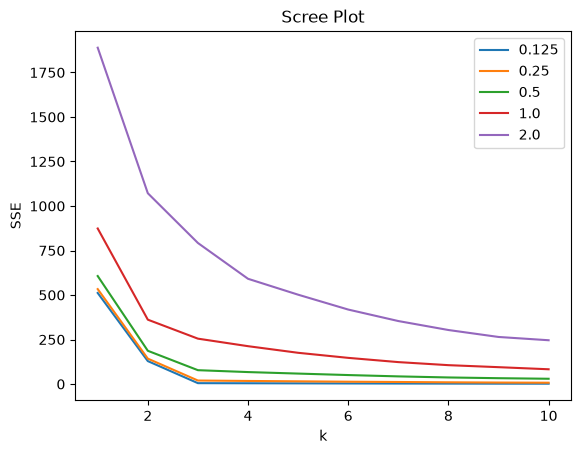

In [121]:
########## ========== Q1.3 ========== ##########
# Create a scree plot for each of the datasets. 
# (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

# Source: https://stackoverflow.com/questions/55981638/how-to-create-a-legend-for-a-seaborn-lineplot-with-two-separately-calculated-lin
from sklearn.cluster import KMeans

# drop the group column from each of the dataframes so we are left with the numerical x1 x2 data of the points
scree0_125 = df0_125.drop("group", axis=1)
scree0_25 = df0_25.drop("group", axis=1)
scree0_5 = df0_5.drop("group", axis=1)
scree1_0 = df1_0.drop("group", axis=1)
scree2_0 = df2_0.drop("group", axis=1)

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree0_125).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '0.125').set(title="Scree Plot", xlabel="k", ylabel="SSE")

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree0_25).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '0.25')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree0_5).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '0.5')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree1_0).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '1.0')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scree2_0).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label = '2.0')

plt.legend()

##### Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$.

Note: by commenting out the curve for scree2_0 we are able to observe that the curve for scree1_0 is the same and hidden underneath it.

The curve for noise level 0.125 shows SSE starting around 500 at k=1, dropping to ~125 at k=2, dropping again to near 0 at k=3, and remaining constant for the remaining k values. The curve for noise level 0.25 sits slightly above the former curve: the SSE at points k=1, k=2, and k=3 are marginally higher, then between k=3 to k=10 the SSE very gradually decreases from above 0 to near 0. At noise level 0.5, we see a large jump between the curves. At k=1, SSE is now around 600. At k=2, SSE is closer to ~200. At k=3, SSE is closer to ~75. Similarly to noise=0.25, the curve from k=3 to k=10 steadily and gradually decreases, however it does not reach near 0 and is closer to SSE=~50. At noise level 1.0, SSE starts around SSE starts at above 800 at k=1, drops to ~350 at k=2, then drops to ~250 at k=3. The slope of the curve between k=3 to k=10 is notably steeper than the other curves, falling from ~250 to ~100. There is a very large gap between the curves of noise level 1.0 and 2.0. The SSE starts very high, at more than 1750. it drops to a little more than 1000 at k=2, which is still greater than the starting SSE of the 1.0 curve. There ins't much of a distinct elbow at k=3 but there is a slightly more visible one at k=4, which sits at around 600 SSE. The curve from k=4 to k=10 is even steeper than that of the 1.0 curve, and the SSE is still at around 300 by the time k=10 is reached.

In general, across almost all the curves, we see 2 elbows, one at k=2 and another at k=3. The drop between SSE at k=1 and k=2 is very steep, and compartively the drop between k=2 and k=3 is much more shallow. Across all curves, at k=2, the elbow is quite clear, however at k=3, the angle of the elbow gradually becomes more obtuse as the noise increases. This is particularly evident when we compare the curves for noise level 0.5 and 1.0/2.0: the elbow at k=3 in the 0.5 curve is sharp because the drop between k=3 to k=10 is quite shallow, however in the 1.0/2.0 curve the elbow at k=3 is close to being indistinguishable from the rest of curve from k=3 to k=10.

When trying to choose a k, it is very clear in the scree plots of noise levels 0.125, 0.25, and 0.5 that k=2 or k=3 would be ideal. The initial curve from k=1 to k=2 significantly reduces the SSE, and from k=2 to k=3 there is another distinct drop. The curves after k=3, especially in the 0.125 and 0.25 plots, show very slight improvements in reducing the SSE. This demostrates that 2 clusters may begin to show the distinctions in the data, and 3 clusters is sufficient to separate most of the observations, and anything more than 3 is unnecessary as it introduces more clusters with minimal improvement. This becomes less clear in the curve for noise levels 1.0 and 2.0: while there is still a steep drop between k=1 and k=2, the drop between k=2 and k=3 and much less distinct, and the improvements in reducing the SSE following k=3 are steeper. Additionally, the SSE in these curves is overall significantly greater. From k=2 to k=3, the SSE drops from ~350 to ~250 in the 1.0 curve, and ~1100 to ~800 in the 2.0 curve: both of these SSE's are quite large. From k=3 to k=10, the SSE drops from ~250 to ~100 in the 1.0 curev, and ~800 to ~300 in the 2.0 curve. This makes the case for k=2 stronger, as it brings the most significant decrease to the SSE, but it also makes the case for k=4 to k=10 stronger, as these k values continue to decrease the SSE in a way that may be considered significant/meaningful. In general, with a higher noise level, there is a reduced ability to definitely select a k.

##### Q1.4: Explain the intuition of the elbow, using this numerical simulation as an example.

The elbow shows a tradeoff between number of clusters and error. We want to figure out how many clusters we need to best identify the underlying groupings of the observations. In general, for clustering, increasing the number of clusters decreases the error: we observe this phenomenon well in the curve for noise levels 1.0, and especially 2.0. However, the elbow can show where increasing k no longer **significantly** improves the error. When increasing k no longer significantly decreases the error, it indicates that we have captured the underlying patterns in the data to a sufficient enough point that if we were to continue to increase k, it would bring little benefit. There may be multiple elbows in the curve, and the elbow we choose is dependent on the type of analyses we intend to do.

In this example, we know that we have 3 groups (a, b, and c), so let's say that our objective is not to assess the relationship between x1 and x2 but to separate and compare the observations. We need to determine how many clusters is "sufficient" in capturing the underlying patterns. In the simulation, we observed elbows at k=2 and k=3. In the curves for noise level 0.125 and 0.25, the choice of k=3 is obvious as the SSE at these points is close to 0. Since we want to separate the observations, k=3 gives us the cleanest separation with the fewest clusters. In the curve for noise levels 0.5/1.0, although we already talked about the fact that increased noise makes it more difficult to select a distinct k, we are still likely to choose k=3. The presence of an elbow at k=3 indicates that the improvement following it is minimal- even though the elbow is much harder to see in the curves for 1.0, it is still there.

It makes sense to choose the greatest k value which is also a distinct elbow to ensure we are maximizing the separation between observations: a distinct elbow = a significant and meaningful decrease in SSE, larger k value = generally lower SSE. A "distinct elbow" is subjective, but I am using it in the sense that after a certain k, elbows show so little meaningful change in SSE that the scree curve appears continuous. For noise level 0.5/1.0, the elbow at k=2 is stronger, but in this context we can conclude that the drop between k=2 and the elbow at k=3 is still mearningful for separating the observations. Using the elbow intuition to choose k, we end up with k=3 which is the same as the known number of groups we started with. This only instance where this doesn't track is when the noise level is 2.0, because in this case the elbow at k=4 is more apparent than the elbow at k=3. This goes back to the previous question- when the level of noise become too high, it makes it harder to definitively select a k. There can still be what is argued as a meaningful decrease in SSE between k=3 and k=4, but for both k values the SSE is still very high, so it would be difficult to attain accurate representation regardless.

### *Reflection on AI assistance
In your own words without generative AI.

In this assignment, AI was able to provide a big improvement for me. It correctly pointed out a simple error in my code where I had written df1_0 instead of df2_0. This error, while very small, made a big difference in my output, as I completely missed the scree curve of df2_0 and conflated it with df1_0. This limited the extent of my written analysis, especially as the df2_0 scree curve further exaggerates the patterns of overall high SSE and smoother curves/lack of elbows. It also impacted my responses for Questions 1.3 and 1.4, so it was important that I fixed this issue. If not for double checking my work with AI, I would have completely missed this small mistake. This time, I asked Claude to only review my code for accuracy, as in previous times it has made suggestions relating to style that I felt were unnecessary or didn't personally like, and I think this was a more efficient way of using AI assistance.